# 03 · 参数校验、修改课程与课程计划


## 资料来源与当天目标

本篇对应 14 天规划的 **day03 课程计划 JSR303**。承接第二篇已经介绍的新增课程、统一异常与接口联调，继续完成请求校验、课程编辑、课程计划查询及新增 / 修改。

| 资料 | 本篇依据 |
|---|---|
| 《第2章 内容管理模块v3.1.docx》 | 延用 day02 下载的整章讲义；百度预览 174 页；本篇覆盖 5.7 JSR303、第 6 节修改课程、第 7 节查询计划、第 8 节新增 / 修改计划与 Bug 修改 |
| day03 的`代码/xuecheng-plus-project.zip` | 已下载并静态核对 11 个 POM、校验 DTO、Controller、Service、Mapper XML 和 HTTP 文件；与 day02 的同名包是不同文件 |
| day03 的`资料`目录 | 另有`实战资料.zip`；本篇不将该包内容当作已核对的依据，项目实战任务随 day04 展开 |
| [网盘分享](https://pan.baidu.com/s/16iXzw7cFDk3FqG9DfPqbdg?pwd=6633) | 提取码`6633`；Java 项目《学成在线》企业级开发实战 → 学成在线项目—资料 |

**当天成果**：不合法请求能得到统一提示；编辑页能回显并保存课程；课程计划按“章 → 小节 → 媒资”展示；添加空章也能在列表中出现。

> 原课程实现、讲义示例和“补充 / 校正”分别标注。Java 代码是需要放回相应工程的教学片段，未编译或启动课程服务；6 张讲义原图作为 Notebook 附件，可离线阅读。


## 1. 当天开发顺序与四个接口

先明确接口和数据关系，再写校验及 SQL，能避免前端字段、模型和实现相互错位。

| 功能 | HTTP 契约 | 核心对象 |
|---|---|---|
| 课程回显 |`GET /content/course/{courseId}` |`CourseBaseInfoDto` |
| 修改课程 |`PUT /content/course` |`EditCourseDto → CourseBaseInfoDto` |
| 查询计划树 |`GET /content/teachplan/{courseId}/tree-nodes` |`List<TeachplanDto>` |
| 新增 / 修改计划 |`POST /content/teachplan` |`SaveTeachplanDto`；返回 void |

开发顺序：校验依赖与 DTO → Controller 触发校验 → 统一错误 → 课程回显与修改 → 两级计划查询 → 保存计划 → 空章和排序排错。

`courseId`标识课程，`id`在计划 DTO 中标识某个章或小节，`parentid`标识所属父计划。这三个值不能互换。


## 2. Bean Validation：规范、实现与 Spring 的分工

每个接口都手写“名称不能为空”，代码重复且规则容易不一致。Bean Validation 可以把基本约束集中声明在模型上。

**Bean Validation**是 Java 对对象属性施加约束的规范。课程沿用“JSR303”称呼；常用的 Bean Validation 2.0 对应 JSR380，增加 / 标准化了更多约束能力。

| 名称 | 职责 |
|---|---|
| JSR303 / 后续 Bean Validation 规范 | 规定约束、校验器、分组等机制 |
| Hibernate Validator | 校验规范的实现，不等于使用 Hibernate ORM 操作数据库 |
|`spring-boot-starter-validation` | Spring Boot 的校验依赖入口 |
|`@Validated` | Spring 提供的校验触发 / 分组支持 |
|`javax.validation.constraints` | 本课程版本使用的约束注解包 |

在 base 工程声明依赖；day03 的 content-api 也直接声明了该 Starter：

```xml
<dependency>
  <groupId>org.springframework.boot</groupId>
  <artifactId>spring-boot-starter-validation</artifactId>
</dependency>
```

版本由 parent 的依赖管理确定。本课程使用 Spring Boot`2.3.7.RELEASE`、Spring Cloud`Hoxton.SR9`、Alibaba`2.2.6.RELEASE`、MyBatis-Plus`3.4.1`、MySQL 驱动`8.0.30`；Swagger Starter 为`1.9.0.RELEASE`，保持前两篇的工程基线。

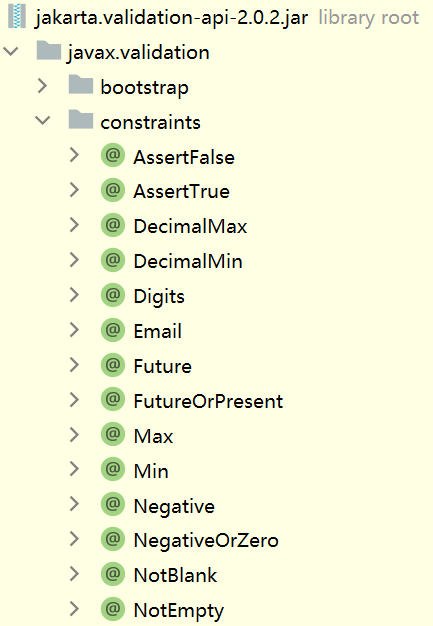

原图来源：第二章“5.7.2 统一校验实现”。截图依赖名为`jakarta.validation-api-2.0.2.jar`，内部包仍是`javax.validation`。不要仅凭 artifact 名称判断 import；Spring Boot 3 / Jakarta Validation 3 的`jakarta.validation`包不能直接搬到本课程的 Boot 2 工程里。


## 3. 常用约束：空值、空串与空格不是同一件事

“不能为空”需要明确是哪种空，否则表单可能通过了与预期不同的规则。

| 约束 | 主要含义 | 容易混淆的边界 |
|---|---|---|
|`@NotNull` | 值不为 null | 字符串`""`、`" "`仍可通过 |
|`@NotEmpty` | 字符串 / 集合等不为 null 且非空 | 字符串纯空格仍可通过 |
|`@NotBlank` | 字符串不为 null 且含非空白字符 | 仅用于字符序列，不用于 Long |
|`@Size(min=10)` | 长度 / 集合大小至少为 10 | 通常允许 null，需与必填约束组合 |
|`@Min / @Max` | 数值下限 / 上限 | 不负责把值设为必填 |
|`@Positive` | 数值严格大于 0 | null 通常可通过，要配`@NotNull` |
|`@Pattern` | 字符串匹配正则 | null 通常可通过 |
|`@Email` | 邮箱格式 | 还需单独表达必填 |
|`@Null` | 值必须为 null | 适合表达新增时由系统生成的字段 |

例如原`users`同时使用`@NotEmpty`和`@Size(min=10)`：null 由前者拦截；1 个字符由长度规则拦截；空串可能产生两条提示；10 个空格仍可能满足这两条规则。

**补充正例**：课程名使用`@NotBlank`再限制长度；ID 使用`@NotNull + @Positive`。  
**反例**：在`Long id`上使用`@NotEmpty`，校验器可能报不支持该类型，而不是得到“ID 为空”的预期结果。

> 注解按其定义判定值，不会自动 trim、修正字段、查询数据库或判断课程归属。输入规范化与业务检查需要另行实现。


## 4. DTO 上声明规则：哪些是原实现，哪些仍没检查

`AddCourseDto`承载前端表单，在字段旁定义约束，新增与编辑共同使用。

day03 代码的核心片段：

```java
@NotEmpty(message = "新增课程名称不能为空",
          groups = ValidationGroups.Inster.class)
@NotEmpty(message = "修改课程名称不能为空",
          groups = ValidationGroups.Update.class)
private String name;

@NotEmpty(message = "适用人群不能为空")
@Size(min = 10, message = "适用人群内容过少")
private String users;

@NotEmpty(message = "课程分类不能为空")
private String mt;

@NotEmpty(message = "课程分类不能为空")
private String st;

@Size(min = 10, message = "课程描述内容过少")
private String description;
```

原 DTO 还给`grade / charge`设置非空规则；`teachmode / pic`只有 Swagger 的 required 描述，没有对应必填约束。description 只有 Size，null 可以通过；这与“描述必须填写”是不同要求。

讲义局部 DTO 用 BigDecimal，day03 代码包价格实际仍为 Float。这里按实际源码理解；统一金额类型的补充见第二篇，不能只换 DTO 就认为全链路金额已经精确。

**怎么用**：先列字段要求，再选择注解，最后把 null、空串、空格、临界长度作为不同请求测试。只看 DTO 上出现了注解，不足以确认整个接口的校验生效。


## 5. Controller 触发校验：先读 JSON，再检查对象

DTO 上的约束只描述规则，HTTP 请求还需要校验触发点。

day03 新增和修改方法在`@RequestBody`参数上使用`@Validated`：

```java
@PostMapping("/course")
public CourseBaseInfoDto createCourseBase(
        @RequestBody @Validated(ValidationGroups.Inster.class)
        AddCourseDto dto) {
    Long companyId = 1232141425L; // 课程暂未接入认证
    return courseBaseInfoService.createCourseBase(companyId, dto);
}

@PutMapping("/course")
public CourseBaseInfoDto modifyCourseBase(
        @RequestBody @Validated(ValidationGroups.Update.class)
        EditCourseDto dto) {
    Long companyId = 1232141425L;
    return courseBaseInfoService.updateCourseBase(companyId, dto);
}
```

流程是`HTTP JSON → 消息转换器生成 DTO → 按指定分组校验 → 成功才执行 Controller 方法 → Service`。这类请求体约束失败通常产生`MethodArgumentNotValidException`。

| 情况 | 原因与处理 |
|---|---|
| 合法 JSON，DTO 字段违反约束 | 请求体校验失败，提取字段提示 |
| JSON 语法错误 / 字段类型无法转换 | 还没进入正常 Bean 校验，通常是`HttpMessageNotReadableException` |
| Service 判断机构不匹配 | 业务异常，不能靠必填注解解决 |
| 直接 new DTO 再调用 Service | 不会仅因为字段有注解就自动走 Controller 校验 |

`@Valid`是 Bean Validation 的级联校验标记，在 Spring MVC 请求体上也可触发默认组校验；`@Validated`可明确选择分组。嵌套对象 / 集合要按需声明`@Valid`级联，不能认为外层校验会自动递归所有对象。


## 6. 校验失败怎样返回统一错误

如果让请求校验异常进入通用 Exception 分支，页面会收到笼统错误。专门处理可以保留具体字段提示。

在`GlobalExceptionHandler`增加下面的方法，沿用课程 HTTP **500** 与`RestErrorResponse.errMessage`契约：

```java
@ResponseBody
@ExceptionHandler(MethodArgumentNotValidException.class)
@ResponseStatus(HttpStatus.INTERNAL_SERVER_ERROR)
public RestErrorResponse methodArgumentNotValidException(
        MethodArgumentNotValidException e) {
    List<String> errors = e.getBindingResult().getFieldErrors().stream()
            .map(error -> error.getDefaultMessage())
            .collect(Collectors.toList());
    String message = String.join(",", errors);
    log.warn("请求参数校验失败：{}", message);
    return new RestErrorResponse(message);
}
```

这里使用 Java 8 的`Collectors.toList`；需引入`java.util.stream.Collectors`。日志文案是补充写法，原代码用 StringUtils.join 拼接。

```json
{
  "errMessage": "课程名称不能为空,适用人群内容过少"
}
```

响应是格式示意：触发的规则和提示取决于选择的分组，错误顺序不应作为前端或测试的稳定约定。不能期待多个字段错误必然按 DTO 声明顺序返回。

**补充**：原处理只提取`getFieldErrors()`，自定义跨字段 / 类级约束还可能产生对象级错误。完善时可处理`getAllErrors()`，或返回字段名、错误代码和提示组成的列表，但需同步前端契约。

原课程把校验失败设为 500；一般 HTTP 设计常用 400 或 422。要更改状态码就同时调整前后端，不能把本例写成“原课程已经使用 400”。缺失 body、JSON 错误等也要有明确异常分支。


## 7. 分组校验：同一字段在不同操作下要求不同

新增订单的编号由系统生成，修改订单又必须携带编号。一套规则无法同时表达这两种输入条件。

**校验分组**用 Java 类型标识一组规则，在执行校验时选择需要的组。原 base 工程定义：

```java
package com.xuecheng.base.exception;

public class ValidationGroups {
    public interface Inster {}
    public interface Update {}
    public interface Delete {}
}
```

`Inster`是课程代码原拼写。讲义有`execption`包名误拼，实际代码是`exception`；引用已有类时保持类名与包名一致。

| 操作 | 可表达的规则 |
|---|---|
| 新增 | 系统生成 ID 应为空；表单名称必填 |
| 修改 | ID 必填且有效；名称必填 |
| 删除 | 通常只需定位资源与确认权限 |

分组只是选择约束，不会自动选择 Service 分支，也不会自动新增、修改、删除数据。课程计划接口按是否传`id`决定操作，这是接口逻辑，和校验组是两件事。

**继承模型**：`EditCourseDto extends AddCourseDto`会继承父类属性上的约束；执行哪些规则仍取决于激活的组。继承 DTO 不是只复制字段名字。


## 8. 默认分组陷阱：为什么名称被校验，人群却没被校验

day03 Controller 只激活 Inster 或 Update，name 的约束属于对应组，而 users、mt、st 等未写 groups 的约束属于`Default`。

**默认组**是`javax.validation.groups.Default`。原三个分组是独立空接口，未继承 Default，因此选择 Inster 不会自动执行所有默认规则。

| 原配置 | 实际激活的规则 |
|---|---|
|`@Validated`不指定组 | Default；不自动执行只属于 Inster / Update 的名称约束 |
|`@Validated(Inster.class)` | Inster；默认组字段可能漏检 |
|`@Validated(Update.class)` | Update；同样可能漏掉默认组字段 |

这个问题更值得注意：day03 的新增 Service 已注释掉大部分手写必填检查。若默认规则未执行，不能指望原 Service 自动兜住被注释的校验。

**补全方案一**：保留原分组声明，在 Controller 同时选择业务组和 Default：

```java
@Validated({ValidationGroups.Inster.class, Default.class})
// 用于新增请求体参数，import javax.validation.groups.Default

@Validated({ValidationGroups.Update.class, Default.class})
// 用于修改请求体参数
```

**补全方案二**：让分组接口继承 Default，Controller 保持原注解：

```java
public class ValidationGroups {
    public interface Inster extends Default {}
    public interface Update extends Default {}
    public interface Delete {}
}
```

选择一种与团队约定一致的方式。普通多组校验没有自动的先后顺序；需要阶段顺序才考虑 GroupSequence。

> 验证场景：新增请求名称合法，但 users 只有一个字、mt 为空。修复后两项都应被拒绝；只测试空名称，会漏掉这个问题。


## 9. Controller 校验与 Service 业务检查

“分类代码非空”不代表分类存在，“课程 ID 大于 0”也不代表课程属于当前机构。

| 检查位置 | 适合的规则 |
|---|---|
| 请求 DTO / Controller | 必填、长度、格式、数值范围 |
| Service | 课程存在、机构归属、分类父子关系、收费规则、业务状态是否允许 |
| 数据库约束 | 主键、唯一性、必要的非空与一致性约束 |

例如`charge=201001`时价格必须大于 0，是关联字段的业务规则。可先保留 Service 判断；需要通用跨字段约束时，再设计类级校验器。

自定义约束通常包含：声明注解并指定`@Constraint` → 实现`ConstraintValidator` → 定义支持类型及 null 语义 → 在 DTO 上使用并确认校验触发。课程第 5.7.4 节只提出手写或自定义方案，不提供完整实现。

**正例**：Controller 拦格式错误，Service 再核对数据库课程与身份。  
**反例**：前端下拉框只显示合法分类，就取消后端分类检查；或`@Validated`生效后删除机构权限判断。

业务层也可能被其他入口调用。需要方法级 Bean Validation 时，应单独配置 Spring 方法校验与代理入口；它不是给字段加注解后自动发生的事情。


## 10. 修改课程的业务流程与数据边界

点击“编辑”先回显当前信息，保存后进入课程计划页面。页面应编辑已有课程，而不是再创建一门课程。

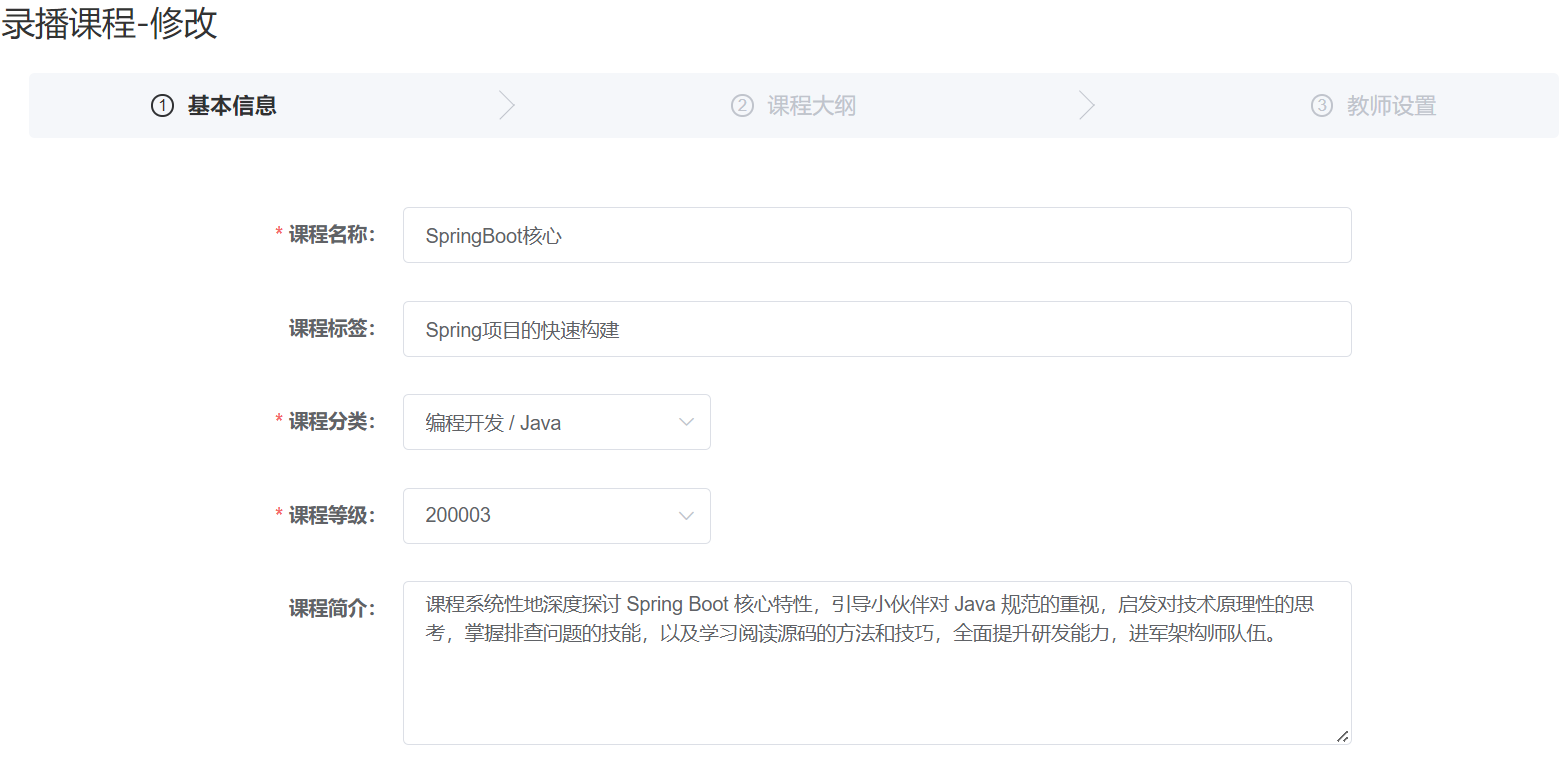

原图来源：第二章“6.1.1 业务流程”。

`列表选择课程 → GET 按 ID 回显 → 修改表单 → PUT 保存 → 返回最新 DTO → 进入计划编辑`

本次修改涉及`course_base`和`course_market`；基本表设置修改时间`changeDate`。创建时间、机构归属、审核 / 发布状态等系统字段不能随表单任意覆盖。

讲义写“任何时候都可以编辑”，因为编辑内容和审核发布过程另有业务安排。复现本日功能先按课程约定处理；真实项目的可编辑状态应由明确规则决定，不能擅自把“已发布不可编辑”当成当天既有代码行为。

**补充**：讲义提到修改人，day03 实现只显式设置修改时间；修改人需要登录身份信息与实际字段赋值，暂时没有自动实现。


## 11. EditCourseDto：修改必须有 ID

新增和修改表单大部分字段相同，修改再增加要操作的课程 ID，因此课程使用继承复用字段。

原`EditCourseDto extends AddCourseDto`只有`Long id`和 Swagger 描述。**Swagger required 不负责拒绝缺失 ID**，需要补上运行时约束。

以下是补全片段，配合第 8 节的默认组处理方案：

```java
@Data
public class EditCourseDto extends AddCourseDto {
    @NotNull(message = "课程ID不能为空",
             groups = ValidationGroups.Update.class)
    @Positive(message = "课程ID必须大于0",
              groups = ValidationGroups.Update.class)
    private Long id;
}
```

`@NotNull`拒绝 null，`@Positive`拒绝 0 和负数；之后 Service 再检查课程存在与机构归属。Long 的数值比较和对象相等要区分：比较机构 ID 使用`equals / Objects.equals`，不能用`==`判断两个包装对象代表的业务值是否相同。

**怎么用**：修改接口分别发送没有 id、id 为 0、不存在的 id、其他机构的 id。它们应在相应层失败，不能都变成“修改成功”。


## 12. 查询课程回显：复用聚合结果，也要检查归属

编辑表单需要基本信息与营销信息，复用第二篇的`getCourseBaseInfo`能够保持新增和回显结构一致。

原 Controller 核心：

```java
@GetMapping("/course/{courseId}")
public CourseBaseInfoDto getCourseBaseById(@PathVariable Long courseId) {
    return courseBaseInfoService.getCourseBaseInfo(courseId);
}
```

| 查询步骤 | day03 代码状态 |
|---|---|
| 按 ID 查 CourseBase | 不存在返回 null |
| 按同 ID 查 CourseMarket | 存在时复制营销信息 |
| 组装 CourseBaseInfoDto | 基本信息与营销信息组合 |
| 设置 mtName / stName | 仍为 TODO，讲义另有完整示例 |
| 校验查询者机构 | 原回显接口没有实现 |

**补充**：机构后台的读接口同样需要数据归属检查。建议业务入口同时接收可信机构身份与课程 ID，确认课程属于该机构，再组装结果；不能因为修改时有权限判断，就认定回显也已受到保护。

查不到课程时，应确定“返回空”还是明确资源不存在的契约。原实现返回 null 不等于已设置 HTTP 404，前端不能只凭请求成功就认为拿到了课程。

分类名称查询也需要处理记录不存在，避免直接对 null 调用`getName()`。原数据状态代码与样例有差异，仍以当前数据库字典为准。


## 13. 修改 Service：基本信息与营销一起保存

页面改变价格后提示保存成功，但重新打开价格没变，说明只更新了基本表，未完成整个修改业务。

day03`updateCourseBase`实际顺序是：取 id → 查课程 → 核对机构 → copyProperties → 设置 changeDate → 更新基本表并检查行数 → **营销 TODO** → 查聚合 DTO。该方法没有`@Transactional`；不能将新增方法的事务注解当成对整个类所有方法生效。

下面给出**两表修改的补全主流程**，放入已有 Mapper 与`saveCourseMarket`的 Service 实现：

```java
@Transactional
@Override
public CourseBaseInfoDto updateCourseBase(Long companyId, EditCourseDto dto) {
    if (companyId == null || dto == null || dto.getId() == null) {
        XueChengPlusException.cast("请求参数不完整");
    }
    Long courseId = dto.getId();
    CourseBase base = courseBaseMapper.selectById(courseId);
    if (base == null) {
        XueChengPlusException.cast("课程不存在");
    }
    if (!Objects.equals(companyId, base.getCompanyId())) {
        XueChengPlusException.cast("本机构只能修改本机构的课程");
    }
    // 继续校验分类、字典、收费等业务规则
    BeanUtils.copyProperties(dto, base,
            "id", "companyId", "companyName", "createDate", "createPeople",
            "auditStatus", "status", "coursePubId", "coursePubDate");
    base.setChangeDate(LocalDateTime.now());
    if (courseBaseMapper.updateById(base) <= 0) {
        XueChengPlusException.cast("修改课程失败");
    }

    CourseMarket market = new CourseMarket();
    BeanUtils.copyProperties(dto, market);
    market.setId(courseId);
    if (saveCourseMarket(market) <= 0) {
        XueChengPlusException.cast("修改课程营销信息失败");
    }
    return getCourseBaseInfo(courseId);
}
```

需引入`java.util.Objects`。示例保留原模型及保存方法，把关键系统属性列入 copyProperties 的排除项；实际团队也可使用逐字段赋值或专用映射器。

**价格规则**继续在营销保存中检查收费价格。课程 DTO 价格为 Float；本片段没有擅自改变全工程金额类型。

> 正例：从数据库读取原机构，再与可信身份比较，最后修改可编辑字段。反例：先把请求机构复制到实体，再与请求里的机构比较；这样比较的是客户端自己提交的数据。


## 14. 修改事务、空值与并发覆盖

两表修改必须一起提交。给公共修改方法加`@Transactional`并经 Spring bean 调用，营销保存失败要让异常离开事务方法。

| 问题 | 应对方向 |
|---|---|
| 营销失败，基本表已经更新 | 本地事务回滚两部分修改 |
| Mapper 返回 0 但没抛异常 | 明确检查业务预期并抛出异常 |
| 普通异常被 catch 后返回成功 | 避免吞掉需要回滚的失败 |
| DTO 的 null 覆盖了原字段 | 明确接口是完整表单保存还是局部更新 |
| 两人同时编辑同一课程 | 版本号 / 条件更新等并发冲突方案 |

BeanUtils 默认会复制 null，实体已经从数据库读取也不能自动保留被 null 覆盖的属性。另一方面，MyBatis-Plus 的更新字段策略还会影响 null 是否写入数据库；这可能出现“对象里已经为空，但数据库未变”的差异。

**怎么用**：本课程 PUT 按编辑表单保存理解，明确每个字段是否必填、可清空或保持原值。不能简单把所有 null 都忽略，否则用户主动清空的值也无法保存。

事务保障同一次操作整体成功，不自动防止两个编辑者互相覆盖。需要乐观锁时要增加版本字段、插件与冲突响应，不能只声明`@Transactional`就宣称并发编辑已解决。


## 15. 课程编辑的请求与验收

先独立验证回显、修改、再次回显，再到页面检查字段和下一步跳转。

```http
### 先回显；40 必须替换为测试环境的真实课程 ID
GET http://localhost:63040/content/course/40

### 保存课程基本信息与营销
PUT http://localhost:63040/content/course
Content-Type: application/json

{
  "id": 40,
  "name": "Spring Boot 核心实践",
  "users": "已经掌握 Java 基础的开发学习者",
  "mt": "1-3",
  "st": "1-3-2",
  "grade": "204001",
  "teachmode": "200002",
  "description": "通过课程案例学习接口开发、数据访问和项目调试。",
  "tags": "Spring Boot",
  "charge": "201001",
  "price": 99.9,
  "originalPrice": 129.9
}

### 再次回显，确认价格和名称都更新
GET http://localhost:63040/content/course/40
```

分类、等级、教学模式代码必须按自己环境核对，样例不是已执行的有效数据证明。

检查：修改 ID 不变；机构、创建时间与系统状态未被表单覆盖；changeDate 更新；营销值保存；其他机构 ID 被拒绝；第二次写入失败时基本表也恢复原值。

失败输入至少包含：缺 ID、短 users、空分类、收费价格为 0、不存在课程、其他机构课程。应在修复默认组后验证这些组合，避免只测空名称。


## 16. 课程计划的数据模型：章、小节与媒资

课程计划是课程大纲，内容管理页面按章显示小节，每个小节可关联一条视频记录。

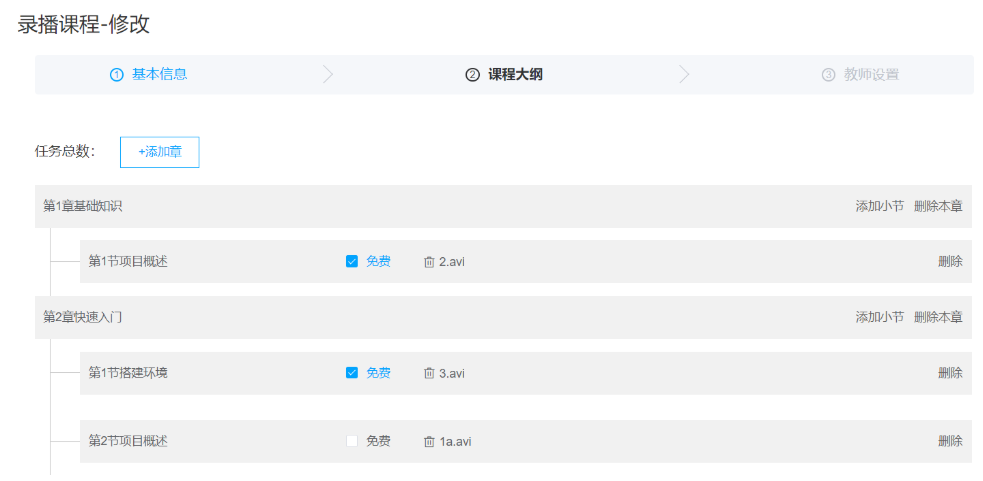

原图来源：第二章“7.1.1 业务流程”。

```text
课程 74
├─ 章 247：基础知识（parentid=0，grade=1）
│  ├─ 小节 248：项目介绍（parentid=247，grade=2）
│  └─ 小节 249：环境准备（parentid=247，grade=2）
└─ 章 250：接口开发（可以暂时没有小节）
```

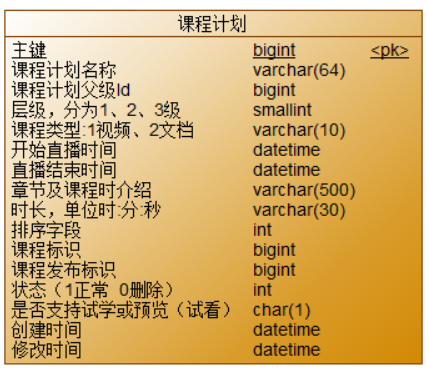

原图来源：第二章“7.1.2 数据模型”。

| teachplan 字段 | 用途 |
|---|---|
|`id / courseId` | 节点主键 / 所属课程 |
|`parentid / grade` | 父节点 / 层级 |
|`pname` | 章或小节名称 |
|`orderby` | 同级排序 |
|`mediaType` | 媒体类型，值要按实际业务约定 |
|`isPreview` | 是否可试看，课程按字符串`"0" / "1"`传递 |
|`startTime / endTime` | 直播开始 / 结束时间 |
|`createDate / changeDate` | 创建 / 修改时间 |

**资料不一致**：PO 注释写 1、2、3 级，旧响应样例出现 grade 2 / 3 和中间根节点；本日新增请求与查询 SQL 使用“章 grade=1、parentid=0；小节 grade=2、parentid=章 ID”。本篇统一按当天接口模型讲解，不能把旧层级样例与当前请求混用。

grade 的 Java 类型是 Integer，JSON 示例使用数字。课件中字符串数字可能被转换，不应把宽松转换当作明确的数据契约。


## 17. TeachplanDto 与计划媒资关系

数据库一行一个节点，HTTP 响应却需要嵌套孩子和关联文件信息，因此返回 DTO 继承 Teachplan 后增加两项：

```java
@Data
public class TeachplanDto extends Teachplan {
    private TeachplanMedia teachplanMedia;
    private List<TeachplanDto> teachPlanTreeNodes;
}
```

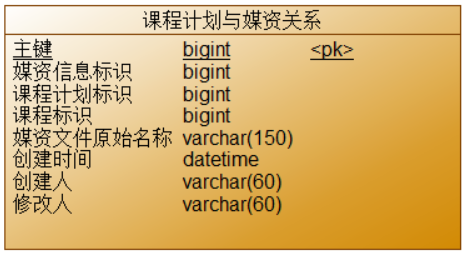

原图来源：第二章“7.1.2 数据模型”。

| 关系 | 模型 / 注意点 |
|---|---|
| 一章有多个小节 |`teachPlanTreeNodes`集合 |
| 一个小节关联一条媒资关系 |`teachplanMedia`对象 |
| 媒资文件与关联行 |`mediaId`是文件标识；关联表`id`是另一主键 |
| 媒资关系定位小节 |`teachplanId`对应小节 ID |

代码中的 TeachplanMedia.mediaId 是 **String**，表结构示意图却写 bigint，应以实际表和 PO 映射为准。`mediaFilename`映射原列`media_fileName`；代码 PO 没有讲义旧响应中的 coursePubId 属性。

查询接口示意（只保留必要字段，ID 均为教学示意）：

```json
[
  {
    "id": 247,
    "courseId": 74,
    "parentid": 0,
    "grade": 1,
    "pname": "基础知识",
    "teachPlanTreeNodes": [
      {
        "id": 248,
        "courseId": 74,
        "parentid": 247,
        "grade": 2,
        "pname": "项目介绍",
        "isPreview": "1",
        "teachplanMedia": {
          "id": 8001,
          "teachplanId": 248,
          "courseId": 74,
          "mediaId": "media-001",
          "mediaFilename": "项目介绍.mp4"
        }
      }
    ],
    "teachplanMedia": null
  }
]
```

这里只查询已经存在的关系，不负责上传视频、转码或新增绑定；媒资管理在后续天数展开。


## 18. 联表查询：先理解平面结果

两级计划可以用 teachplan 自连接，小节再左连接媒资表；SQL 返回的是平面行，不会自动返回 JSON 树。

| 平面行 | 章 ID | 小节 ID | 媒资关联 ID |
|---|---|---|---|
| 第 1 行 | 247 | 248 | 8001 |
| 第 2 行 | 247 | 249 | null |
| 第 3 行 | 250 | null | null |

正确结果应把前两行合成一章、两个小节；第三行保留为空章。

**LEFT JOIN**保留左表节点，即使右边没有匹配行。计划自连接必须保留没有小节的章；媒资连接必须保留未绑定视频的小节。

day03 源码却使用`INNER JOIN teachplan two`，因此章 250 在查询阶段已经消失，后续 Mapper 组树和前端刷新无法把它恢复。

**补充**：子节点所属课程应与父章一致，媒资关系也应指向同课程。写入时要验证这些关系；联表条件也可固定课程条件，防止错误数据跨课程混入。


## 19. 完整查询与 resultMap 补全

下面是**修正空章、时间属性、试看字段及空关联对象的 Mapper 片段**。配合带`@Param`的 Mapper 方法使用，namespace 与当前工程一致：

```java
public interface TeachplanMapper extends BaseMapper<Teachplan> {
    List<TeachplanDto> selectTreeNodes(@Param("courseId") Long courseId);
}
```

`@Param`来自`org.apache.ibatis.annotations.Param`。原代码单个 Long 参数的 SQL 写`#{id}`，讲义写`#{value}`；简单单参数场景可能直接绑定参数对象，不能断言不同名字必然报错。显式命名能让接口与 SQL 语义一致，也便于以后增加参数。

```xml
<mapper namespace="com.xuecheng.content.mapper.TeachplanMapper">
  <resultMap id="treeNodeResultMap"
             type="com.xuecheng.content.model.dto.TeachplanDto">
    <id column="one_id" property="id"/>
    <result column="one_pname" property="pname"/>
    <result column="one_parentid" property="parentid"/>
    <result column="one_grade" property="grade"/>
    <result column="one_media_type" property="mediaType"/>
    <result column="one_start_time" property="startTime"/>
    <result column="one_end_time" property="endTime"/>
    <result column="one_orderby" property="orderby"/>
    <result column="one_course_id" property="courseId"/>
    <result column="one_course_pub_id" property="coursePubId"/>
    <result column="one_is_preview" property="isPreview"/>
    <collection property="teachPlanTreeNodes"
                ofType="com.xuecheng.content.model.dto.TeachplanDto"
                notNullColumn="two_id">
      <id column="two_id" property="id"/>
      <result column="two_pname" property="pname"/>
      <result column="two_parentid" property="parentid"/>
      <result column="two_grade" property="grade"/>
      <result column="two_media_type" property="mediaType"/>
      <result column="two_start_time" property="startTime"/>
      <result column="two_end_time" property="endTime"/>
      <result column="two_orderby" property="orderby"/>
      <result column="two_course_id" property="courseId"/>
      <result column="two_course_pub_id" property="coursePubId"/>
      <result column="two_is_preview" property="isPreview"/>
      <association property="teachplanMedia"
                   javaType="com.xuecheng.content.model.po.TeachplanMedia"
                   notNullColumn="media_record_id">
        <id column="media_record_id" property="id"/>
        <result column="media_id" property="mediaId"/>
        <result column="media_filename" property="mediaFilename"/>
        <result column="media_teachplan_id" property="teachplanId"/>
        <result column="media_course_id" property="courseId"/>
      </association>
    </collection>
  </resultMap>

  <select id="selectTreeNodes" resultMap="treeNodeResultMap">
    SELECT
      one.id AS one_id,
      one.pname AS one_pname,
      one.parentid AS one_parentid,
      one.grade AS one_grade,
      one.media_type AS one_media_type,
      one.start_time AS one_start_time,
      one.end_time AS one_end_time,
      one.orderby AS one_orderby,
      one.course_id AS one_course_id,
      one.course_pub_id AS one_course_pub_id,
      one.is_preview AS one_is_preview,
      two.id AS two_id,
      two.pname AS two_pname,
      two.parentid AS two_parentid,
      two.grade AS two_grade,
      two.media_type AS two_media_type,
      two.start_time AS two_start_time,
      two.end_time AS two_end_time,
      two.orderby AS two_orderby,
      two.course_id AS two_course_id,
      two.course_pub_id AS two_course_pub_id,
      two.is_preview AS two_is_preview,
      m.id AS media_record_id,
      m.media_id AS media_id,
      m.media_fileName AS media_filename,
      m.teachplan_id AS media_teachplan_id,
      m.course_id AS media_course_id
    FROM teachplan one
    LEFT JOIN teachplan two
      ON two.parentid = one.id AND two.course_id = one.course_id
    LEFT JOIN teachplan_media m
      ON m.teachplan_id = two.id AND m.course_id = one.course_id
    WHERE one.parentid = 0 AND one.course_id = #{courseId}
    ORDER BY one.orderby, one.id, two.orderby, two.id
  </select>
</mapper>
```

`isPreview`是页面可编辑字段，原树查询没有显式查询 / 映射它；本片段补上，避免保存后回显缺失。状态和其他字段如需返回，应按契约继续列出并映射。

原 Mapper 把`one_stratTime / two_stratTime`映射到`stratTime`，实际 PO 字段是`startTime`。别名可以自定义，但 property 必须是存在的 Java 属性，不能只改 SQL 名字却保留错误 property。


## 20. MyBatis 如何把多行还原成对象树

resultMap 告诉 MyBatis：哪些列属于章，哪些属于小节，哪些属于关联视频。

| XML 元素 | 本例含义 |
|---|---|
|`id` | 标识当前层对象，帮助嵌套映射合并相同身份的行 |
|`result` | 普通列到属性的映射 |
|`collection` | 一对多：章中的小节列表；ofType 指定元素类型 |
|`association` | 一对一：小节的媒资对象；javaType 指定对象类型 |
|`notNullColumn` | 关联列非空时才生成对应子对象 |

章 ID 247 在 SQL 中出现两次，顶层 id 映射使它合成一个对象；两个不同小节 ID 分别进入集合。这里是一条联表 SQL 的嵌套结果映射，不是每个小节再发一次查询的嵌套 select。

**空关联判断**：小节存在但无视频时，媒资主键为 null。应以`media_record_id`判断媒资对象存在，不能因为小节 ID 或 courseId 非空，就生成看似已绑定的视频对象。

**补充**：业务要求每个小节最多一条媒资关系，数据库和写入逻辑应维护这个约束。若同一小节有多条媒资记录，单个 association 无法如实表达一对多，不能期待 resultMap 自动解决脏数据。

查询顺序来自 SQL 的 ORDER BY；id 映射负责识别对象，不负责业务排序。两级树需求固定时这套写法足够，任意深度树再考虑第二篇的递归 CTE + 内存组树方案。


## 21. 新章不显示：从数据库到页面逐层定位

讲义第 8.5 节描述：HTTP Client 保存没问题，前端却看不到刚新增的一级目录。保存接口成功与列表查询正确是不同的验收目标。

**定位顺序**：

1. 查看保存请求是否新增章：id 未传、parentid=0、grade=1。
2. 在测试库确认该课程下已经插入章记录。
3. 直接调用计划树 GET，检查响应是否包含该章。
4. 若响应缺章，执行同条件 SELECT，检查 JOIN 是否把空章过滤。
5. 修复查询后再回到页面确认刷新与渲染。

| SQL 写法 | 无小节的章 | 无视频的小节 |
|---|---|---|
| 章 INNER JOIN 小节 | 丢失 | 小节存在时取决于媒资连接 |
| 章 LEFT JOIN 小节，小节 LEFT JOIN 媒资 | 保留 | 保留 |

改成 LEFT JOIN 后也要小心：若把`two.grade=2`等子表条件放在 WHERE，空子行无法满足条件，又会过滤空章。需要保留空章的子表过滤应放在 ON，并明确实际数据规则。

> 正例：只新增章、没有任何小节，GET 仍能返回章且孩子列表为空。反例：加一个小节后“神奇地恢复”，就把问题归因于前端缓存。

chapter、child 的主键映射与空子对象判断也要检查。原时间字段误拼可能在有非空时间数据时暴露；仅用时间全部为 null 的数据测试，不能证明映射属性正确。


## 22. 一个保存接口区分新增与修改

课程计划用同一个 POST 处理新增章、新增小节和修改节点，以是否传递`id`选择分支。

| 请求 |`id` |`parentid / grade` | 行为 |
|---|---|---|---|
| 新增章 | null / 不传 | 0 / 1 | 添加根层节点，排到同级末尾 |
| 新增小节 | null / 不传 | 真实章 ID / 2 | 添加到指定章下 |
| 修改节点 | 真实计划 ID | 原父节点 / 原级别 | 修改名称、试看等允许字段 |

原 Controller：

```java
@PostMapping("/teachplan")
public void saveTeachplan(@RequestBody SaveTeachplanDto dto) {
    teachplanService.saveTeachplan(dto);
}
```

原 SaveTeachplanDto 包含 id、pname、parentid、grade、mediaType、courseId、coursePubId、isPreview，没有 orderby、页面控件状态等字段。当前 Controller 没有`@Validated`，DTO 也没有约束注解，不能因为课程保存有校验，就认定计划保存也已校验。

方法返回 void，课程未指定 204 等状态，通常是成功 200 和空响应体。前端应按这个契约处理，不能收到空 body 就判定失败，也不能假设响应携带新计划 ID；需刷新树或另行调整保存响应契约。

**字段校正**：旧修改样例传`teachPlanId`，当前 DTO 读`id`。如果 JSON 转换没有替它映射，id 仍为空，就会按新增处理。字段必须与真实 DTO 一致，不能指望相似名字自动绑定。


## 23. 原保存 Service：数量、排序和更新分支

先理解实际代码，再判断哪些条件没有覆盖。

| 分支 | day03 源码做法 |
|---|---|
| 新增 | DTO 复制到新 Teachplan；按 courseId + parentid 查询同级数；设置 orderby；insert |
| 修改 | selectById；DTO 复制到查出的对象；updateById |
| getTeachplanCount | 查询数量后返回`count+1`，名字叫 Count 但返回的是待使用序号 |
| 事务与失败检查 | 保存方法无`@Transactional`，没有检查 insert / update 返回行数 |

原排序辅助方法：

```java
private int getTeachplanCount(Long courseId, Long parentId) {
    LambdaQueryWrapper<Teachplan> wrapper = new LambdaQueryWrapper<>();
    wrapper.eq(Teachplan::getCourseId, courseId)
           .eq(Teachplan::getParentid, parentId);
    Integer count = teachplanMapper.selectCount(wrapper);
    return count + 1;
}
```

本课程 MyBatis-Plus 3.4.1 的 selectCount 返回 Integer；不要直接照搬后来版本的类型假设。

**讲义与代码差异**：讲义辅助方法返回 count，调用方再加 1；当天代码辅助方法已经加 1，调用方直接使用。两种写法各自等价，混用才会多加一次；方法名应反映返回含义。

原修改没有检查查出的节点是否为 null。不存在的 ID 可能在复制或后续调用中报异常；它也没有检查课程和父章归属，不足以防止错误修改与跨课程操作。


## 24. 排到最后：count+1 为什么可能错

数量只表示有几条记录，最大排序号表示当前末尾位置；删除后两者不再相同。

| 当前同级 orderby | count+1 | max+1 | 判断 |
|---|---|---|---|
| 无节点 | 1 | 1 | 都可作为起点 |
| 1、2、3 | 4 | 4 | 连续序号时都可用 |
| 1、3 | 3 | 4 | count+1 与已有 3 重复 |
| 2、5 | 3 | 6 | count+1 甚至排不到末尾 |

**补充查询思路**：

```sql
SELECT COALESCE(MAX(orderby), 0) + 1
FROM teachplan
WHERE course_id = #{courseId}
  AND parentid = #{parentId};
```

排序作用域是同课程、同父节点。不同章的小节各自有一套序号，不能只按 courseId 取全部计划的最大值。还应明确已删除节点是否参与排序，不能悄悄把 status 的规则省略。

**并发问题**：A、B 同时读取 max=5，都计算 6，两个事务仍可能插入重复序号。仅加`@Transactional`不自动把“读最大值 → 插入”串行化。

可在同一事务中锁定确定的父节点行，顶层章则锁定课程行，再计算序号并写入；所有相关写入路径要遵守相同锁规则。也可设计排序唯一约束与冲突重试，需同时考虑后续排序交换操作。

查询可使用 orderby 再加 ID 排序，保证重复序号时结果可预测，但它只稳定显示，不能消除重复序号这个数据问题。


## 25. 新增计划要守住课程与父子关系

直接信任 courseId、parentid、grade，会让小节挂到其他课程的章下，或形成错误层级。

| 新增检查 | 应满足的规则 |
|---|---|
| 课程 | 课程存在，属于当前可信机构，可执行本次编辑 |
| 章 | parentid=0，grade=1 |
| 小节 | 父节点存在，是章，且与本次 courseId 一致；grade=2 |
| 名称 | 非空白，长度符合表及业务约定 |
| 试看 | 按规则仅允许`"0" / "1"`，明确适用级别 |
| 媒体类型 | 按当前类型约定，不混用注释里的 1 / 2 和旧样例里的字典代码 |
| 系统字段 | 排序、创建时间、发布关联等由后端生成或受控赋值 |
| 数据保存 | 检查实际写入结果；失败抛业务异常 |

父节点检查应从数据库读取真实关系，不能只看 ID 的数值或名称。当前接口缺少身份传递，完善时要同步调整 Controller 与 Service 的可信身份入口；不能把客户端 courseId 当成权限证明。

**正例**：课程 74 的小节仅挂到课程 74 的章下，排序在该章内部计算。  
**反例**：发送 courseId=74、parentid 却属于课程 75，仍成功插入。

SaveTeachplanDto 可增加基础约束并在 Controller 参数上触发，关系和身份检查继续放在 Service。新增与修改共用接口时，也应明确两种请求的约束差异，而不是给 id 统一加 NotNull 导致新增全部失败。


## 26. 修改计划：限制可编辑字段与时间赋值

本日“修改计划”主要修改名称和小节是否试看。重设课程、父节点、层级或发布标识会改变树的业务关系，应使用明确功能与校验流程。

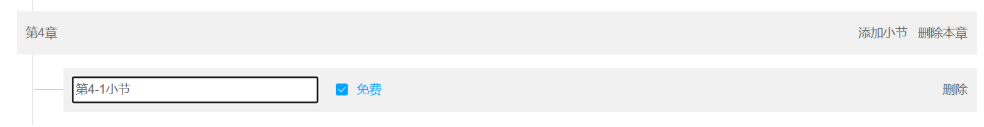

原图来源：第二章“8.1.1 业务流程”。

原代码`BeanUtils.copyProperties(dto, teachplan)`可能把 DTO 里的 courseId、parentid、grade 等一并复制。补全时先查节点，核对身份和所属课程，再只赋值允许编辑的字段。

以下是**修改分支核心片段**，以请求 courseId 必填且前面已经完成机构校验为前提：

```java
Teachplan existing = teachplanMapper.selectById(dto.getId());
if (existing == null) {
    XueChengPlusException.cast("课程计划不存在");
}
if (!Objects.equals(existing.getCourseId(), dto.getCourseId())) {
    XueChengPlusException.cast("课程计划与课程不匹配");
}
// 已校验名称、试看值和节点层级；本次不改变树的父子关系
existing.setPname(dto.getPname());
if (dto.getIsPreview() != null) {
    existing.setIsPreview(dto.getIsPreview());
}
existing.setChangeDate(LocalDateTime.now());
if (teachplanMapper.updateById(existing) <= 0) {
    XueChengPlusException.cast("修改课程计划失败");
}
```

这段没有执行真正的机构授权，也没有替代请求校验；完整入口仍需第 25 节的检查。其他可编辑字段应按确定的契约逐项增加；要移动节点时另行校验新父节点、层级和排序。

**自动填充补充**：Teachplan 的 createDate / changeDate 标有`@TableField(fill=...)`，该注解不等于时间自动生成。代码包未发现注册的`MetaObjectHandler`，因此需实现填充处理器或在 Service 中明确赋值，并用真实保存结果确认。

创建时间应只在新增时设定；修改时间在修改时更新。客户端提交 createDate、orderby 或页面`ctlBarShow`等字段，不应成为后端系统赋值的依据。


## 27. 保存与再查询的 HTTP 请求集合

一次保存后再查询，才能确认节点、父子关系、名称及试看都已正确回显。

以下 ID 为教学示意：courseId 使用真实测试课程，parentid 和修改 id 使用查询返回的实际节点 ID。JSON 使用当前 DTO 的`id`，层级为数字，试看为字符串。

```http
### 新增空章
POST http://localhost:63040/content/teachplan
Content-Type: application/json

{
  "courseId": 74,
  "parentid": 0,
  "grade": 1,
  "pname": "基础知识"
}

### 查询，取得刚创建的章 ID，并验证空章已出现
GET http://localhost:63040/content/teachplan/74/tree-nodes

### 新增小节；247 替换为前一步返回的章 ID
POST http://localhost:63040/content/teachplan
Content-Type: application/json

{
  "courseId": 74,
  "parentid": 247,
  "grade": 2,
  "pname": "项目介绍",
  "isPreview": "0"
}

### 修改小节；248 替换为真实小节 ID
POST http://localhost:63040/content/teachplan
Content-Type: application/json

{
  "id": 248,
  "courseId": 74,
  "parentid": 247,
  "grade": 2,
  "pname": "项目介绍与学习目标",
  "isPreview": "1"
}

### 再查，确认修改没有新增第二条小节
GET http://localhost:63040/content/teachplan/74/tree-nodes
```

也可以把完整`http://localhost:63040`存入`http-client.env.json`的 content_host，再用`{{content_host}}`拼接路径，保持第二篇的变量约定。

旧修改样例还混用课程 ID、字符串 grade、`cousePubId`误拼和页面控件字段。本例仅提交实际输入字段；字段不认识时可能被 JSON 配置忽略或拒绝，不应依赖隐式兼容掩盖契约错误。


## 28. 前后端联调与验收矩阵

页面操作应和独立 HTTP 请求取得相同结果：编辑课程 → 保存 → 进入计划 → 新增章 / 节 → 修改名称 / 试看 → 刷新。

| 场景 | 验收目标 |
|---|---|
| 修复分组后的短 users / 空 mt | 同时触发默认规则，不能只校验名称 |
| 修改缺 ID | 返回明确参数提示，不进入数据库操作 |
| 修改课程名称及价格 | 两表同时改变，再回显一致 |
| 修改其他机构课程 | 拒绝；读取回显也有对应权限规则 |
| 基本表更新后营销失败 | 两表回滚，不出现部分修改 |
| 无计划课程 | 合理空列表，不将空视为系统错误 |
| 只有章、没有小节 | 章仍返回，不产生虚构小节 |
| 小节未绑定媒资 | 小节保留，媒资对象为空 |
| 一章多个小节 | 一个章对象，孩子正确合并且有序 |
| 时间字段非空 | 正确映射 startTime / endTime，不使用 stratTime |
| 新增不同章的小节 | 各章排序独立，父子所属课程正确 |
| 修改小节 | ID 和记录数量不变，名称 / 试看再查一致 |
| 已删除造成排序空洞 | 新序号在末尾，不与现有序号重复 |
| 并发新增 | 按已设计策略避免 / 处理序号冲突 |
| 无效父节点 / 跨课程父节点 | 明确拒绝，不插入非法关系 |

**浏览器排错补充**：本日新增了 PUT。第二篇 CORS 补充片段只示意 GET / POST / OPTIONS，继续直连联调时应在实际 content API 配置中允许 PUT，并核对来源、请求头和预检响应。仅允许 POST 不够。

`HTTP 返回成功 → GET 树结果正确 → 页面刷新并展示正确`是三项独立检查。请求失败先看 Network 的 URL、方法、payload、响应，再看服务日志；请求正确而页面错误，再核对`teachPlanTreeNodes / teachplanMedia`的拼写与类型。

以上是复现验收目标，本笔记没有执行课程服务或数据库测试。


## 29. 来源覆盖与待补全项对照

| 讲义范围 | 本篇内容 |
|---|---|
| 5.7.1—5.7.2 统一校验 | 2—6 |
| 5.7.3 分组、5.7.4 扩展规则 | 7—9 |
| 6 修改课程 | 10—15 |
| 7 查询课程计划 | 16—20 |
| 8 新增 / 修改计划、8.5 Bug 修改 | 21—28 |
| 9 项目实战：删除、排序、师资等 | 留 day04，本篇只说明与当天功能直接相关的排序问题 |

| 实际 day03 代码 / 讲义差异 | 本篇给出的补全方向 |
|---|---|
| Controller 选独立分组，通用规则在 Default | 同时选 Default，或让组继承 Default |
| EditCourseDto 的 ID 只有 Swagger 标记 | 添加运行时必填和正值约束 |
| 回显无机构判断、分类名称仍 TODO | 补数据归属及分类查询 / 空值检查 |
| 修改课程营销 TODO、修改方法无事务 | 完成两表写入、事务及行数检查 |
| 讲义要求左连接，SQL 和源码却写内连接 | 以空章场景验证 LEFT JOIN |
| 映射用 stratTime，PO 用 startTime | 对齐真实属性与列别名 |
| 查询未显式映射 isPreview | 补试看字段，验证编辑后回显 |
| 旧层级样例为 2 / 3，当前新增为 1 / 2 | 按当前课程与 parentid=0 模型统一 |
| 修改样例 teachPlanId，DTO 字段 id | 使用当前字段，防止误走新增 |
| count+1 依赖序号连续 | max+1 处理空洞，并另行设计并发控制 |
| 保存计划缺存在、归属、行数检查 | 分别补边界检查和失败响应 |
| 自动填充注解但未发现处理器 | 注册 MetaObjectHandler 或明确赋值 |

静态核对范围包括原讲义、day03 代码包 11 个 POM、相关 DTO / PO / Controller / Service / Mapper 及 HTTP 文件；生成时检查 Markdown、JSON / XML 片段和原图附件，保留来源哈希。**未编译、启动项目、执行 SQL或运行接口测试。**


## 30. 面试提示

**面试提示**：

| 问题 | 回答要点 |
|---|---|
| JSR303 校验如何生效？ | Starter 提供实现；DTO 声明约束；MVC 请求体使用 Valid / Validated 触发；失败统一处理 |
| NotNull、NotEmpty、NotBlank 有什么区别？ | 分别检查非 null、非空、非空白字符串；注意支持类型和 null 语义 |
| Size(min=10) 能代替必填吗？ | 通常不能，null 可通过；与必填约束组合，纯空格也要考虑 |
| Valid 和 Validated 有何关系？ | Valid 支持标准级联；Validated 是 Spring 的校验与分组支持；HTTP 触发和方法代理校验要区分 |
| 分组为什么导致漏校验？ | 独立业务组不自动激活 Default；同时指定或通过继承统一通用规则 |
| Controller 已校验，Service 还查什么？ | 存在性、归属、分类关系、收费和业务状态等 |
| 修改课程为什么要事务？ | 基本与营销两表属于一次业务修改，失败应整体回滚；原当天代码仍有 TODO |
| 新章保存成功为什么看不到？ | 内连接过滤了无孩子的章；应左连接并检查子表条件位置 |
| MyBatis 如何映射树？ | id 标识对象；collection 映射孩子；association 映射媒资；notNullColumn 控制空关联 |
| count+1 和 max+1 有什么不同？ | 数量不代表末尾序号；max+1 处理空洞，但两者都需另外处理并发竞争 |
| 事务可以防并发重复排序吗？ | 不自动防止相同读取结果；还要锁、约束、重试等相应设计 |
| 修改计划如何避免改错关系？ | 先查节点并授权，核对课程，只赋值允许编辑字段，移动节点使用专门规则 |

用“新增空章 → 查询树 → 新增小节 → 修改试看 → 再查”的具体过程解释接口、SQL、映射和校验，再补上原代码与修正的差异，就能把知识点串成完整的开发过程。
